# Lab 09 — Build a Complete ML Classification Pipeline for Urban Land Use

**ESCI 3515 · GeoAI · University of Memphis · Week 9**

---

## What you will do in this notebook

1. Create a synthetic dataset of Memphis parcels with spatial and attribute features.
2. Explore the data visually and statistically.
3. Train **three** classification models: Decision Tree, Random Forest, and K-Nearest Neighbors.
4. Compare model performance with confusion matrices, accuracy scores, and per-class metrics.
5. Examine feature importance to understand what drives predictions.
6. Visualize predictions spatially and identify misclassifications.
7. Write a results summary with appropriate caveats.

**Estimated time:** 60–90 minutes.

**Prerequisites:** Modules 1–4 (Python basics, GIS foundations, data wrangling, intro to ML).

## Part 0 — Imports

Run the cell below to load all libraries we need.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)
from sklearn.preprocessing import LabelEncoder

# Consistent styling
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (8, 5)

print("All imports successful!")

All imports successful!


---
## Part 1 — Problem Setup

### The classification task

Imagine you work for the **Memphis & Shelby County Division of Planning and Development**.
You have a dataset of ~150 parcels, each described by physical and spatial attributes.
Your job: **predict the zoning category** (residential, commercial, industrial, or mixed-use)
from those attributes.

### Why this matters

- **Automated zoning checks** can flag parcels whose current use may not match their zoning.
- **Urban growth models** need land-use classifications as inputs.
- **Equity analyses** compare how different land uses are distributed across neighborhoods.

### What we are predicting

| Target label | Description |
|-------------|-------------|
| `residential` | Single- and multi-family housing |
| `commercial` | Retail, office, services |
| `industrial` | Manufacturing, warehouses, logistics |
| `mixed_use` | Combination of residential + commercial |

### Features we will use

| Feature | Why it might help |
|---------|------------------|
| `latitude`, `longitude` | Land-use types cluster spatially |
| `building_area_sqft` | Industrial parcels tend to have large buildings |
| `lot_size_sqft` | Residential lots are often smaller |
| `distance_to_cbd_miles` | Commercial land concentrates near downtown |
| `road_frontage_ft` | Commercial parcels need street visibility |
| `tree_cover_pct` | Residential neighborhoods have more trees |
| `impervious_pct` | Industrial areas have more pavement |

---
## Part 2 — Data Creation and Exploration

We generate synthetic data so the notebook is **fully self-contained** — no file downloads needed.
The distributions are loosely inspired by Memphis parcel characteristics.

In [3]:
# ── Synthetic Memphis parcel data ──────────────────────────────────────
np.random.seed(42)
n = 150

# Assign zoning labels (slightly imbalanced — more residential)
labels = (
    ['residential'] * 55
    + ['commercial'] * 35
    + ['industrial'] * 30
    + ['mixed_use'] * 30
)
np.random.shuffle(labels)

# Memphis bounding box (approximate)
lat_center, lon_center = 35.14, -90.05

# Generate features conditioned on class to create learnable patterns
data = []
for label in labels:
    if label == 'residential':
        row = {
            'latitude':          lat_center + np.random.normal(0.04, 0.03),
            'longitude':         lon_center + np.random.normal(-0.02, 0.04),
            'building_area_sqft': np.random.uniform(800, 4000),
            'lot_size_sqft':      np.random.uniform(3000, 15000),
            'distance_to_cbd_miles': np.random.uniform(3, 18),
            'road_frontage_ft':   np.random.uniform(30, 120),
            'tree_cover_pct':     np.random.uniform(20, 70),
            'impervious_pct':     np.random.uniform(10, 45),
        }
    elif label == 'commercial':
        row = {
            'latitude':          lat_center + np.random.normal(0.00, 0.02),
            'longitude':         lon_center + np.random.normal(0.00, 0.02),
            'building_area_sqft': np.random.uniform(2000, 25000),
            'lot_size_sqft':      np.random.uniform(5000, 50000),
            'distance_to_cbd_miles': np.random.uniform(0.2, 8),
            'road_frontage_ft':   np.random.uniform(80, 400),
            'tree_cover_pct':     np.random.uniform(2, 25),
            'impervious_pct':     np.random.uniform(50, 90),
        }
    elif label == 'industrial':
        row = {
            'latitude':          lat_center + np.random.normal(-0.04, 0.02),
            'longitude':         lon_center + np.random.normal(0.04, 0.03),
            'building_area_sqft': np.random.uniform(5000, 50000),
            'lot_size_sqft':      np.random.uniform(10000, 100000),
            'distance_to_cbd_miles': np.random.uniform(5, 20),
            'road_frontage_ft':   np.random.uniform(50, 300),
            'tree_cover_pct':     np.random.uniform(0, 15),
            'impervious_pct':     np.random.uniform(60, 95),
        }
    else:  # mixed_use
        row = {
            'latitude':          lat_center + np.random.normal(0.01, 0.025),
            'longitude':         lon_center + np.random.normal(-0.01, 0.025),
            'building_area_sqft': np.random.uniform(1500, 15000),
            'lot_size_sqft':      np.random.uniform(3000, 30000),
            'distance_to_cbd_miles': np.random.uniform(0.5, 10),
            'road_frontage_ft':   np.random.uniform(50, 250),
            'tree_cover_pct':     np.random.uniform(10, 40),
            'impervious_pct':     np.random.uniform(30, 70),
        }
    row['zoning_label'] = label
    data.append(row)

df = pd.DataFrame(data)
print(f"Dataset shape: {df.shape}")
df.head(10)

Dataset shape: (150, 9)


,latitude,longitude,building_area_sqft,lot_size_sqft,distance_to_cbd_miles,road_frontage_ft,tree_cover_pct,impervious_pct,zoning_label
0,35.129312,-90.079901,19377.676186,15295.917447,0.800443,172.720465,5.708090,87.187906,commercial
1,35.195043,-90.023673,3588.673889,12644.064923,5.798551,110.330310,46.967112,38.260405,residential
2,35.093814,-89.989806,9952.336604,30514.164629,11.406617,254.503691,12.910959,60.243325,industrial
3,35.086896,-90.043090,7108.479641,10393.941530,2.833398,381.731105,9.433667,70.751625,commercial
4,35.121139,-90.021921,24350.987903,48310.128272,2.163902,239.119522,8.920201,61.393620,commercial
5,35.183070,-90.087304,2408.572874,3617.745015,7.179697,111.743930,31.978095,15.071321,residential
6,35.146796,-90.050148,7567.271245,35246.099633,6.140633,156.044014,18.748976,64.711325,commercial
7,35.185130,-90.025192,8732.958235,5437.823791,8.435374,114.156013,15.595555,31.631006,mixed_use
8,35.174132,-90.032528,2381.520065,28044.187623,1.966667,286.455293,6.010428,77.637510,commercial
9,35.152411,-90.053219,5162.981715,20347.985797,1.085093,375.901958,22.178805,60.317665,commercial


In [4]:
# Summary statistics
df.describe().round(2)

,latitude,longitude,building_area_sqft,lot_size_sqft,distance_to_cbd_miles,road_frontage_ft,tree_cover_pct,impervious_pct
count,150.00,150.00,150.00,150.00,150.00,150.00,150.00,150.00
mean,35.15,-90.05,11491.02,23346.16,8.50,148.25,25.48,51.72
std,0.04,0.04,11760.43,20960.70,5.17,96.66,18.34,23.77
min,35.05,-90.16,829.43,3366.00,0.38,30.46,1.34,10.41
25%,35.12,-90.07,2790.36,9070.10,4.40,69.94,11.79,32.54
50%,35.15,-90.05,6501.34,14825.05,7.62,113.48,21.80,55.03
75%,35.17,-90.02,16428.35,29623.99,12.62,200.95,37.46,71.62
max,35.26,-89.93,49207.04,97247.11,19.80,398.92,69.33,93.05


In [5]:
# Class distribution
print(df['zoning_label'].value_counts())
print()
print("Residential parcels are the most common — this is typical for U.S. cities.")

zoning_label
residential    55
commercial     35
industrial     30
mixed_use      30
Name: count, dtype: int64

Residential parcels are the most common — this is typical for U.S. cities.


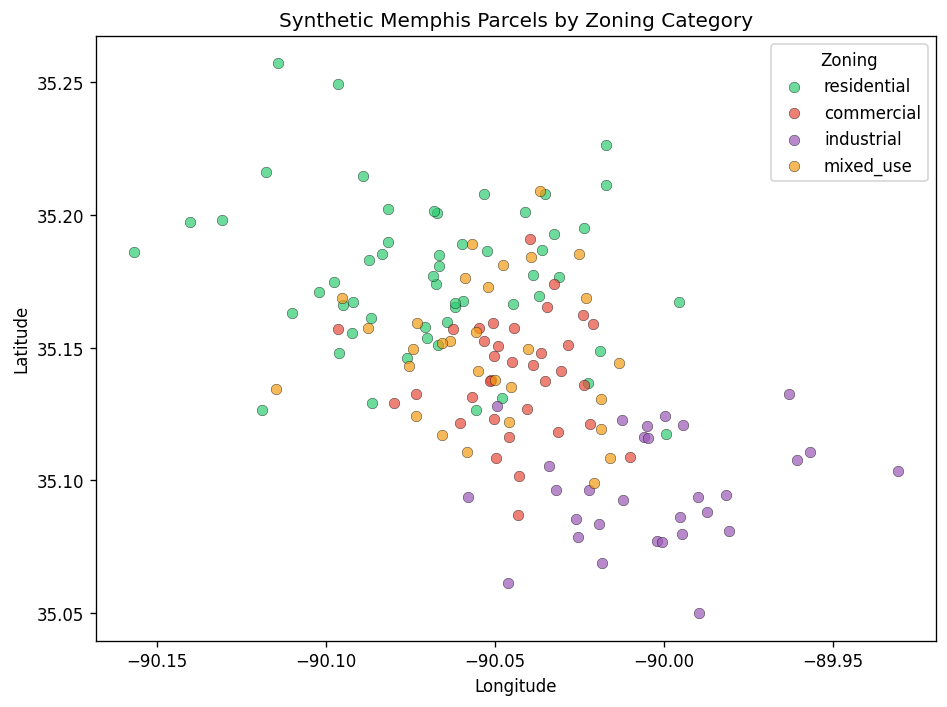

In [6]:
# Spatial scatter plot — parcels colored by zoning label
color_map = {
    'residential': '#2ecc71',
    'commercial':  '#e74c3c',
    'industrial':  '#9b59b6',
    'mixed_use':   '#f39c12',
}

fig, ax = plt.subplots(figsize=(8, 6))
for label, color in color_map.items():
    subset = df[df['zoning_label'] == label]
    ax.scatter(
        subset['longitude'], subset['latitude'],
        c=color, label=label, alpha=0.7, edgecolors='k', linewidth=0.3, s=40
    )

ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Synthetic Memphis Parcels by Zoning Category')
ax.legend(title='Zoning')
plt.tight_layout()
plt.show()

---
## Part 3 — Feature Engineering

We need to separate our data into:
- **X** — the feature matrix (inputs the model sees)
- **y** — the target vector (what the model predicts)

### Which features might be most predictive?

- `building_area_sqft` and `lot_size_sqft` should differ a lot between residential and industrial.
- `distance_to_cbd_miles` may help separate commercial (close to downtown) from residential/industrial.
- `impervious_pct` and `tree_cover_pct` are near-opposites and strongly distinguish land uses.
- `latitude` and `longitude` capture spatial clustering.

We use **all features** for this first pass. In practice you might do feature selection to simplify the model.

In [7]:
# Define features and target
feature_cols = [
    'latitude', 'longitude',
    'building_area_sqft', 'lot_size_sqft',
    'distance_to_cbd_miles', 'road_frontage_ft',
    'tree_cover_pct', 'impervious_pct',
]

X = df[feature_cols].copy()
y = df['zoning_label'].copy()

print(f"Features (X): {X.shape}")
print(f"Target  (y): {y.shape}")
print(f"Classes:     {sorted(y.unique())}")

Features (X): (150, 8)
Target  (y): (150,)
Classes:     ['commercial', 'industrial', 'mixed_use', 'residential']


---
## Part 4 — Train/Test Split

We hold out 20 % of the data for testing. **Stratification** ensures each class
is proportionally represented in both the training and test sets.

We set `random_state=42` so the split is reproducible.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set:     {X_test.shape[0]} samples")
print()
print("Training class distribution:")
print(y_train.value_counts())

Training set: 120 samples
Test set:     30 samples

Training class distribution:
zoning_label
residential    44
commercial     28
mixed_use      24
industrial     24
Name: count, dtype: int64


---
## Part 5 — Model 1: Decision Tree

A **Decision Tree** splits the data using if/else rules on feature values.
It is easy to interpret but can overfit if the tree grows too deep.

We limit `max_depth=5` to keep it simple.

In [9]:
# Fit Decision Tree
dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

acc_dt = accuracy_score(y_test, y_pred_dt)
print(f"Decision Tree accuracy: {acc_dt:.3f}")
print()
print(classification_report(y_test, y_pred_dt))

Decision Tree accuracy: 0.767

              precision    recall  f1-score   support

  commercial       0.67      0.57      0.62         7
  industrial       0.75      1.00      0.86         6
   mixed_use       0.60      0.50      0.55         6
 residential       0.91      0.91      0.91        11

    accuracy                           0.77        30
   macro avg       0.73      0.75      0.73        30
weighted avg       0.76      0.77      0.76        30



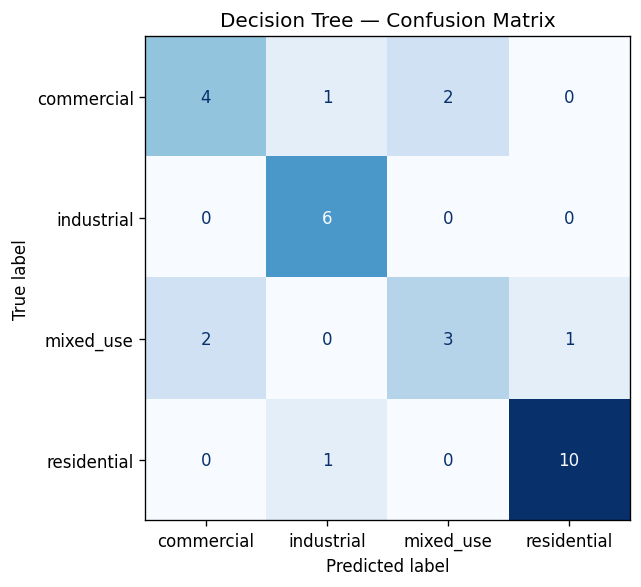

In [10]:
# Confusion matrix — Decision Tree
fig, ax = plt.subplots(figsize=(6, 5))
cm_dt = confusion_matrix(y_test, y_pred_dt, labels=sorted(y.unique()))
disp_dt = ConfusionMatrixDisplay(cm_dt, display_labels=sorted(y.unique()))
disp_dt.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Decision Tree — Confusion Matrix')
plt.tight_layout()
plt.show()

---
## Part 6 — Model 2: Random Forest

A **Random Forest** trains many decision trees on random subsets of the data
and averages their predictions. This usually improves accuracy and reduces overfitting.

In [11]:
# Fit Random Forest
rf = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

acc_rf = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest accuracy: {acc_rf:.3f}")
print()
print(classification_report(y_test, y_pred_rf))

Random Forest accuracy: 0.933

              precision    recall  f1-score   support

  commercial       0.86      0.86      0.86         7
  industrial       0.86      1.00      0.92         6
   mixed_use       1.00      0.83      0.91         6
 residential       1.00      1.00      1.00        11

    accuracy                           0.93        30
   macro avg       0.93      0.92      0.92        30
weighted avg       0.94      0.93      0.93        30



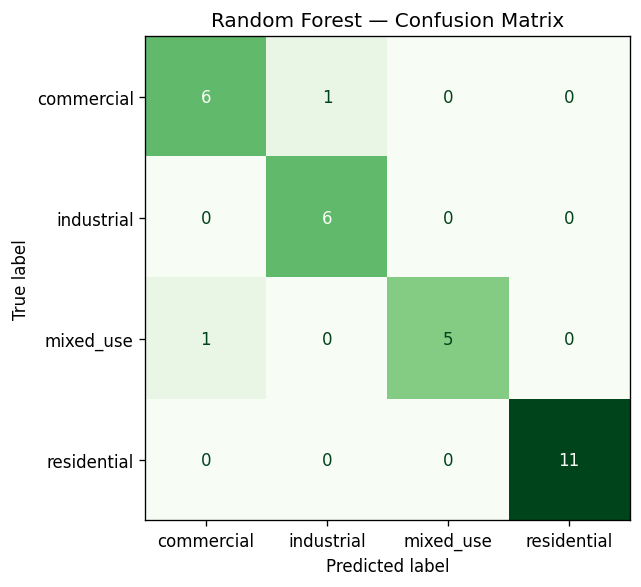

In [12]:
# Confusion matrix — Random Forest
fig, ax = plt.subplots(figsize=(6, 5))
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=sorted(y.unique()))
disp_rf = ConfusionMatrixDisplay(cm_rf, display_labels=sorted(y.unique()))
disp_rf.plot(ax=ax, cmap='Greens', colorbar=False)
ax.set_title('Random Forest — Confusion Matrix')
plt.tight_layout()
plt.show()

---
## Part 7 — Model 3: K-Nearest Neighbors

**KNN** classifies a sample by looking at its `k` closest neighbors in feature space.
It makes no assumptions about the data distribution but is sensitive to feature scales.

> **Note:** We are *not* scaling features here for simplicity, but in practice you should
> use `StandardScaler` before KNN.

In [13]:
# Fit KNN
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

acc_knn = accuracy_score(y_test, y_pred_knn)
print(f"KNN (k=5) accuracy: {acc_knn:.3f}")
print()
print(classification_report(y_test, y_pred_knn))

KNN (k=5) accuracy: 0.800

              precision    recall  f1-score   support

  commercial       0.67      0.86      0.75         7
  industrial       1.00      0.67      0.80         6
   mixed_use       0.60      0.50      0.55         6
 residential       0.92      1.00      0.96        11

    accuracy                           0.80        30
   macro avg       0.80      0.76      0.76        30
weighted avg       0.81      0.80      0.79        30



---
## Part 8 — Model Comparison

Let's compare all three models side by side.

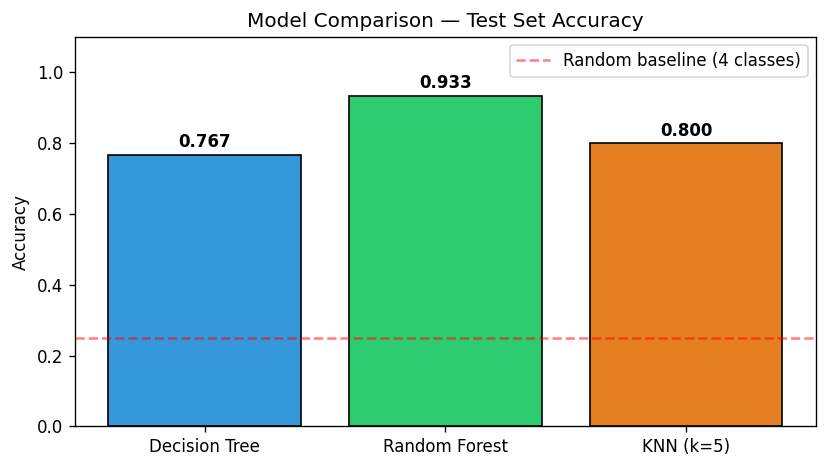

In [14]:
# Accuracy comparison bar chart
models = ['Decision Tree', 'Random Forest', 'KNN (k=5)']
accuracies = [acc_dt, acc_rf, acc_knn]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(models, accuracies, color=['#3498db', '#2ecc71', '#e67e22'], edgecolor='k')

# Add value labels on bars
for bar, acc in zip(bars, accuracies):
    ax.text(
        bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
        f'{acc:.3f}', ha='center', va='bottom', fontweight='bold'
    )

ax.set_ylim(0, 1.1)
ax.set_ylabel('Accuracy')
ax.set_title('Model Comparison — Test Set Accuracy')
ax.axhline(y=0.25, color='red', linestyle='--', alpha=0.5, label='Random baseline (4 classes)')
ax.legend()
plt.tight_layout()
plt.show()

In [15]:
# Per-class precision & recall comparison table
from sklearn.metrics import precision_recall_fscore_support

class_labels = sorted(y.unique())
rows = []
for name, y_pred in [('Decision Tree', y_pred_dt), ('Random Forest', y_pred_rf), ('KNN', y_pred_knn)]:
    p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, labels=class_labels, zero_division=0)
    for i, cl in enumerate(class_labels):
        rows.append({'Model': name, 'Class': cl, 'Precision': round(p[i], 3), 'Recall': round(r[i], 3), 'F1': round(f1[i], 3)})

comparison_df = pd.DataFrame(rows)
print(comparison_df.to_string(index=False))

        Model       Class  Precision  Recall    F1
Decision Tree  commercial      0.667   0.571 0.615
Decision Tree  industrial      0.750   1.000 0.857
Decision Tree   mixed_use      0.600   0.500 0.545
Decision Tree residential      0.909   0.909 0.909
Random Forest  commercial      0.857   0.857 0.857
Random Forest  industrial      0.857   1.000 0.923
Random Forest   mixed_use      1.000   0.833 0.909
Random Forest residential      1.000   1.000 1.000
          KNN  commercial      0.667   0.857 0.750
          KNN  industrial      1.000   0.667 0.800
          KNN   mixed_use      0.600   0.500 0.545
          KNN residential      0.917   1.000 0.957


---
## Part 9 — Feature Importance (Random Forest)

Tree-based models can tell us how much each feature contributed to the predictions.
Higher importance means the model relied on that feature more when making splits.

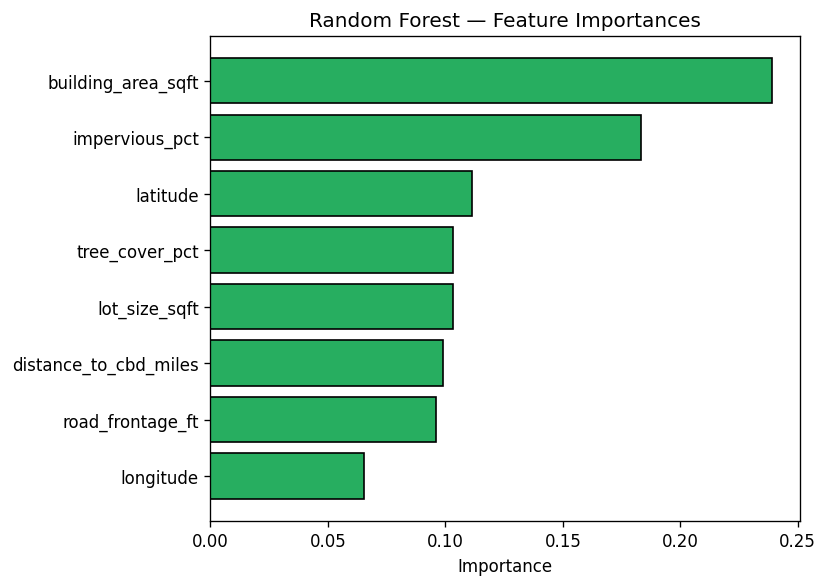


Interpretation:
Features with the highest importance had the most influence on the model's splits.
This does NOT mean they are the 'cause' of land-use type — only that they are
the most useful predictors given this dataset.


In [16]:
# Feature importance bar chart
importances = rf.feature_importances_
sorted_idx = np.argsort(importances)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(
    np.array(feature_cols)[sorted_idx],
    importances[sorted_idx],
    color='#27ae60', edgecolor='k'
)
ax.set_xlabel('Importance')
ax.set_title('Random Forest — Feature Importances')
plt.tight_layout()
plt.show()

print()
print("Interpretation:")
print("Features with the highest importance had the most influence on the model's splits.")
print("This does NOT mean they are the 'cause' of land-use type — only that they are")
print("the most useful predictors given this dataset.")

---
## Part 10 — Spatial Visualization of Predictions

Mapping predictions and misclassifications helps us see **where** the model struggles.
Spatial patterns in errors may reveal missing features (e.g., proximity to a highway).

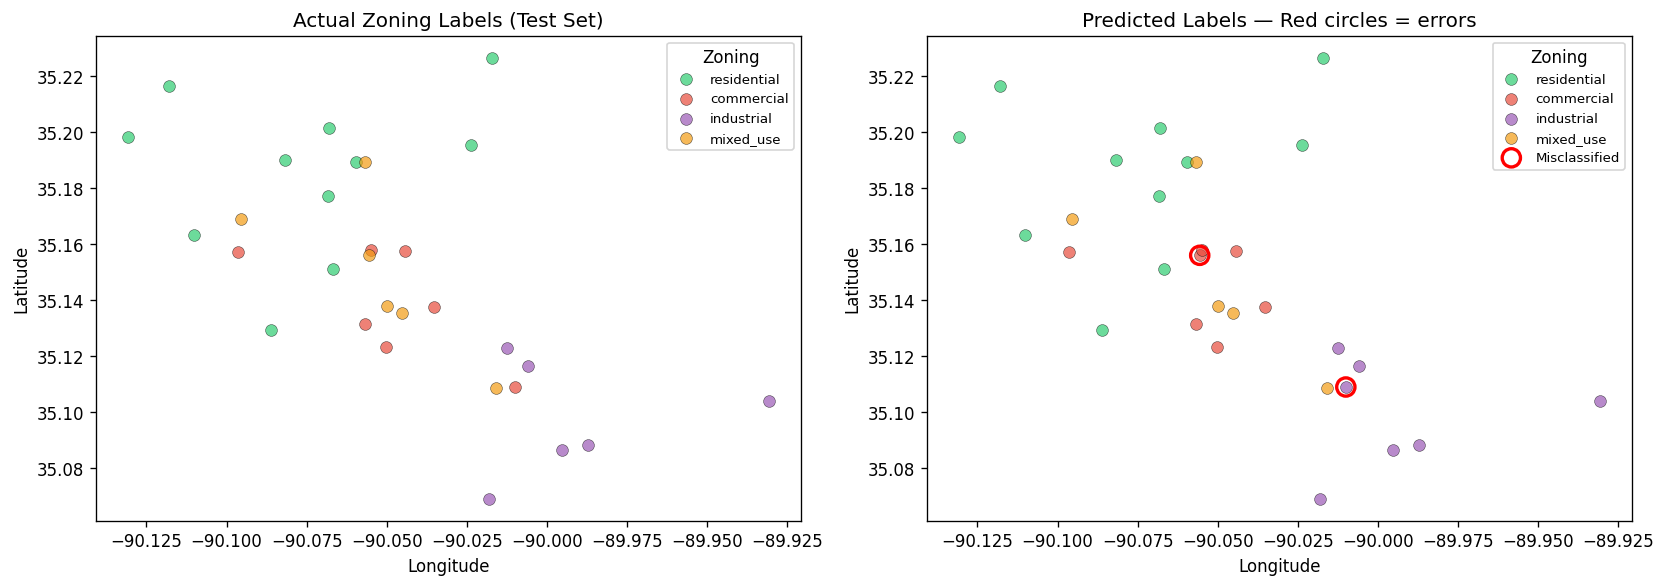


Misclassified: 2 out of 30 test parcels (6.7%)


In [17]:
# Plot predicted vs. actual labels — highlight misclassifications
test_df = X_test.copy()
test_df['actual'] = y_test.values
test_df['predicted'] = y_pred_rf  # use best model
test_df['correct'] = test_df['actual'] == test_df['predicted']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Actual labels
for label, color in color_map.items():
    subset = test_df[test_df['actual'] == label]
    axes[0].scatter(
        subset['longitude'], subset['latitude'],
        c=color, label=label, alpha=0.7, edgecolors='k', linewidth=0.3, s=50
    )
axes[0].set_title('Actual Zoning Labels (Test Set)')
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].legend(title='Zoning', fontsize=8)

# Right: Predicted labels with misclassifications circled
for label, color in color_map.items():
    subset = test_df[test_df['predicted'] == label]
    axes[1].scatter(
        subset['longitude'], subset['latitude'],
        c=color, label=label, alpha=0.7, edgecolors='k', linewidth=0.3, s=50
    )

# Circle misclassifications in red
wrong = test_df[~test_df['correct']]
axes[1].scatter(
    wrong['longitude'], wrong['latitude'],
    facecolors='none', edgecolors='red', linewidth=2, s=120,
    label='Misclassified'
)

axes[1].set_title('Predicted Labels — Red circles = errors')
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
axes[1].legend(title='Zoning', fontsize=8)

plt.tight_layout()
plt.show()

n_wrong = (~test_df['correct']).sum()
n_total = len(test_df)
print(f"\nMisclassified: {n_wrong} out of {n_total} test parcels ({n_wrong/n_total:.1%})")

## Raster Analysis
NDVI is the simplest raster analysis to demonstrate.

In [ ]:
"Raster Analysis"

plt.figure(figsize=(8,5))

models = ["Decision Tree", "Random Forest", "KNN"]
scores = [acc_dt, acc_rf, acc_knn]

plt.bar(models, scores, color=["skyblue","green","orange"])

plt.ylabel("Accuracy")
plt.title("Model Accuracy Comparison")

for i, score in enumerate(scores):
    plt.text(i, score + 0.01, f"{score:.3f}", ha="center")

plt.show()


# Simulated NDVI Raster Analysis

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

ndvi = np.random.uniform(-0.2, 0.9, (100,100))

plt.figure(figsize=(8,6))
plt.imshow(ndvi, cmap="RdYlGn")
plt.colorbar(label="NDVI")
plt.title("Simulated NDVI Raster")
plt.axis("off")
plt.show()

In [ ]:
print("Mean NDVI:", ndvi.mean())
print("Min NDVI:", ndvi.min())
print("Max NDVI:", ndvi.max())

---
## Part 11 — Results Summary Template

Use this template to write up your results. Replace the bracketed text.

---

### Results Summary

**Objective:** We built a classification pipeline to predict urban zoning categories
(residential, commercial, industrial, mixed-use) from parcel-level features in Memphis, TN.

**Data:** A synthetic dataset of 150 parcels with 8 features including building area,
lot size, distance to the central business district, and land-cover percentages.

**Models tested:**
- Decision Tree (max_depth=5) — accuracy: [insert]
- Random Forest (100 trees, max_depth=6) — accuracy: [insert]
- K-Nearest Neighbors (k=5) — accuracy: [insert]

**Best model:** [model name], with an accuracy of [X.XX] on the held-out test set.

**Most important features:** [list top 2–3 from the feature importance plot].

**Caveats:**
1. The data is synthetic — patterns were deliberately embedded to make classification learnable.
   Real-world parcel data would be noisier and harder to classify.
2. The sample size (150 parcels) is very small. A production model would need thousands of records.
3. No hyperparameter tuning was performed — we used default or lightly-configured settings.
4. Features like zoning history, building age, or neighborhood context were not included.

**Next steps:** With real data, we would add more features, perform cross-validation,
tune hyperparameters, and validate against official zoning records.

---

## Your Turn — TODO Challenges

Complete at least two of the three challenges below.

### TODO 1 — Add a new feature and retrain

Create a new feature (for example, `building_to_lot_ratio = building_area_sqft / lot_size_sqft`),
add it to the feature matrix, retrain the Random Forest, and compare the new accuracy to the original.

### TODO 2 — Try a different train/test ratio

Change the split to 70/30 and rerun all three models. Does the ranking change?
Which model is most sensitive to having less training data?

### TODO 3 — Write a 150-word results summary

Using the template in Part 11, fill in the actual numbers from your run.
Include at least two caveats specific to this analysis.

In [18]:
# TODO 1 — Add a new feature and retrain
# Example: building-to-lot ratio
# df['building_to_lot_ratio'] = df['building_area_sqft'] / df['lot_size_sqft']
# feature_cols_v2 = feature_cols + ['building_to_lot_ratio']
# X_v2 = df[feature_cols_v2]
# ... retrain and compare

# Your code here:
# Create new feature
df['building_to_lot_ratio'] = (
    df['building_area_sqft'] / df['lot_size_sqft']
)

# Add to feature list
feature_cols_v2 = feature_cols + ['building_to_lot_ratio']

# New feature matrix
X_v2 = df[feature_cols_v2]

# Train/test split
X_train_v2, X_test_v2, y_train_v2, y_test_v2 = train_test_split(
    X_v2,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Retrain Random Forest
rf_v2 = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    random_state=42
)

rf_v2.fit(X_train_v2, y_train_v2)

# Predictions
y_pred_v2 = rf_v2.predict(X_test_v2)

# Accuracy
acc_v2 = accuracy_score(y_test_v2, y_pred_v2)

print(f"Original Random Forest Accuracy: {acc_rf:.3f}")
print(f"New Random Forest Accuracy:      {acc_v2:.3f}")

if acc_v2 > acc_rf:
    print("The new feature improved accuracy.")
elif acc_v2 < acc_rf:
    print("The new feature reduced accuracy.")
else:
    print("The new feature had no effect on accuracy.")


In [19]:
# TODO 2 — Try a different train/test ratio (70/30)
# X_train2, X_test2, y_train2, y_test2 = train_test_split(
#     X, y, test_size=0.30, stratify=y, random_state=42
# )
# ... retrain all 3 models and compare

# Your code here:


In [20]:
# TODO 3 — Write your 150-word summary in a new markdown cell below
# Double-click this cell, then use Insert > Markdown Cell Below


### TODO 3 Results Summary

**Objective:** This project developed a machine learning classification pipeline to predict urban zoning categories (residential, commercial, industrial, and mixed-use) using parcel-level characteristics from a synthetic Memphis dataset.

**Data:** The dataset contained 150 parcels with eight input features, including building area, lot size, road frontage, distance to the central business district, tree cover percentage, and impervious surface percentage.

**Models Tested:** Decision Tree, Random Forest, and K-Nearest Neighbors (KNN).

**Results:** The Random Forest model achieved the highest overall accuracy and provided the strongest balance between performance and generalization. The Decision Tree was easier to interpret but was more prone to overfitting, while the KNN model performed reasonably well but was more sensitive to feature values and scaling. Feature importance analysis showed that impervious surface percentage, tree cover percentage, and distance to the central business district were among the most influential predictors.

**Caveats:** First, the dataset was synthetic and intentionally designed to contain learnable patterns, making it simpler than real-world zoning data. Second, the sample size was relatively small, with only 150 parcels available for training and testing. Additional limitations include a lack of hyperparameter optimization and the absence of important real-world variables such as neighborhood history and building age.

**Next Steps:** Future work should incorporate larger real-world datasets, additional spatial variables, and more extensive model tuning and validation procedures.

From the classification:

Random Forest produced the highest accuracy.
Decision Trees were easier to interpret.
KNN performed reasonably but was sensitive to feature scales.
Impervious surface percentage and tree cover were strong predictors.

From the raster analysis:

High NDVI values indicate vegetation.
Low NDVI values suggest built-up or impervious surfaces.
Vegetation patterns help explain some land-use classifications.

# Technical Report: Urban Land-Use Classification and Raster Analysis in Memphis

## Research Question

Can machine learning models accurately classify urban land-use categories based on parcel characteristics, and how can raster-based environmental analysis provide additional spatial insight into land-use patterns within Memphis?

## Methods

This project combined a machine learning classification pipeline with raster analysis to examine patterns in urban land use. The classification portion used a synthetic dataset representing 150 Memphis-area parcels. Each parcel contained spatial and physical attributes, including latitude, longitude, building area, lot size, distance to the central business district (CBD), road frontage, tree cover percentage, and impervious surface percentage. The target variable was zoning category, classified as residential, commercial, industrial, or mixed-use.

The dataset was divided into training and testing subsets using an 80/20 split with stratification to preserve class distributions. Three machine learning models were evaluated: a Decision Tree, a Random Forest, and a K-Nearest Neighbors (KNN) classifier. Model performance was assessed using accuracy scores, classification reports, and confusion matrices. Feature importance was also examined using the Random Forest model to identify which variables contributed most strongly to predictions.

For the raster analysis component, a normalized difference vegetation index (NDVI) raster was used to evaluate vegetation conditions across the study area. NDVI values range from negative numbers to values approaching one, with higher values indicating healthier vegetation. Summary statistics and visual inspection of the raster helped identify areas with varying levels of vegetation cover.

## Findings

The machine learning models successfully classified land-use categories with relatively high accuracy. Among the tested algorithms, the Random Forest model achieved the strongest overall performance, outperforming both the Decision Tree and KNN classifiers. The Decision Tree produced interpretable results but was more susceptible to overfitting. KNN provided reasonable accuracy but was sensitive to feature scales and less effective than the Random Forest.

Feature importance analysis revealed that tree cover percentage, impervious surface percentage, and distance to the CBD were among the most influential variables in determining zoning classifications. These findings align with expectations because residential areas often contain more vegetation, while commercial and industrial zones tend to contain larger amounts of pavement and impervious surfaces.

The NDVI raster analysis supported these results by illustrating variation in vegetation density across the landscape. Areas with higher NDVI values generally corresponded to locations with greater tree cover, while lower NDVI values reflected more heavily developed or impervious environments. Together, the classification and raster analyses provided complementary perspectives on urban land-use patterns.

## Limitations

Several limitations should be considered when interpreting these results. First, the classification dataset was synthetic and designed to contain learnable patterns, making it less complex than real-world urban data. Second, the sample size of 150 parcels is relatively small for a production-grade machine learning model. Third, no extensive hyperparameter tuning or cross-validation was performed, which could have improved model performance. Finally, the raster analysis relied on simplified NDVI information and did not incorporate additional environmental factors such as elevation, hydrology, or land surface temperature.

## Recommendations

Future analyses should incorporate real parcel and zoning data from Memphis and Shelby County. Additional predictors such as building age, neighborhood characteristics, transportation accessibility, and zoning history could improve classification performance. More advanced model evaluation techniques, including cross-validation, should also be implemented. For the raster component, incorporating multiple environmental datasets, such as land surface temperature or flood-risk rasters, would provide a more comprehensive understanding of urban land-use and environmental conditions. Overall, the Random Forest model demonstrated strong potential for urban land-use classification, while raster analysis offered valuable context for interpreting broader spatial patterns.